# 06 — Champion vs Challenger financial comparison

**Objective.** Validate the scorecard (champion) against non-linear challengers using the
**cost matrix** from notebook 05, not only AUC/Gini.

Two scikit-learn challengers are compared:
- `HistGradientBoostingClassifier` (default, fast histogram-based boosting)
- `GradientBoostingClassifier` (classical gradient boosting)

Both are trained on the training set and evaluated on the test set.


In [ ]:
import sys, json, os
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from challenger import (
    train_challenger, train_sklearn_gbm, predict_pd,
    compare_models, gini, roc_curves,
)
from cost_matrix import optimal_pd_threshold, total_portfolio_cost
from decision import score_to_pd, optimal_score_threshold

params = json.load(open("../models/scaling_params.json"))
OFFSET, FACTOR, INTERCEPT = params["Offset"], params["Factor"], params["intercept"]
features = json.load(open("../models/selected_features.json"))
t = optimal_pd_threshold()

print(f"Selected features ({len(features)}): {features}")
print(f"Decision threshold PD < {t:.4f}")

## 1. Champion PD from the scorecard

The champion probability of default is derived from the scorecard score via the scaling parameters.
This keeps the comparison aligned with the deployed decision rule.

In [ ]:
y_test = pd.read_parquet("../data/processed/y_test.parquet").squeeze()
test_scores = pd.read_parquet("../data/processed/test_scores_with_target.parquet")["score"]

pd_champion = np.asarray(score_to_pd(test_scores, OFFSET, FACTOR, INTERCEPT))
pd_champion = np.asarray(pd_champion).flatten()
y_test = np.asarray(y_test)

print(f"Champion PD: min={pd_champion.min():.4f}, mean={pd_champion.mean():.4f}, max={pd_champion.max():.4f}")
print(f"Observed default rate: {y_test.mean():.4f}")

## 2. Train the challenger on train data, evaluate on test data

Important: the challenger is fitted on the **training set only**. Evaluating on the training set
would be data leakage and would invalidate the comparison.

In [ ]:
X_train = pd.read_parquet("../data/processed/X_train_woe.parquet")
y_train = pd.read_parquet("../data/processed/y_train.parquet").squeeze()
X_test = pd.read_parquet("../data/processed/X_test_woe.parquet")

challenger = train_challenger(X_train[features], y_train)
pd_challenger = predict_pd(challenger, X_test[features])

print(f"Challenger trained on {X_train.shape[0]} rows, evaluated on {X_test.shape[0]} rows")

## 3. Alternative challenger — sklearn GradientBoostingClassifier

A second non-linear challenger using classical sklearn gradient boosting.
No external dependency is required.

In [ ]:
challenger_alt = train_sklearn_gbm(X_train[features], y_train)
pd_challenger_alt = predict_pd(challenger_alt, X_test[features])

comparison_alt = compare_models(y_test, pd_champion, pd_challenger_alt, threshold_pd=t)
print(comparison_alt.to_string(index=False))

## 4. Financial comparison

Both models use the **same PD cutoff** (1/6) derived from the cost matrix, so the comparison is fair.

In [19]:
comparison = compare_models(y_test, pd_champion, pd_challenger, threshold_pd=t)
print(comparison.to_string(index=False))

champ_cost = comparison.loc[0, "total_cost"]
chall_cost = comparison.loc[1, "total_cost"]
print(f"\nCost difference (challenger - champion): {chall_cost - champ_cost:+.0f} units")

               model      AUC     Gini  total_cost  approval_rate  bad_accepted  good_rejected
Scorecard (Champion) 0.815450 0.630899        79.0       0.453333             7             44
          Challenger 0.765926 0.531852        98.0       0.566667            13             33

Cost difference (challenger - champion): +19 units


## 5. ROC and lift curves

Two visual checks: ranking quality (ROC) and how many defaults are captured in the riskiest deciles.

We have Challenger < Challenger_alt : we choose Challenger_alt

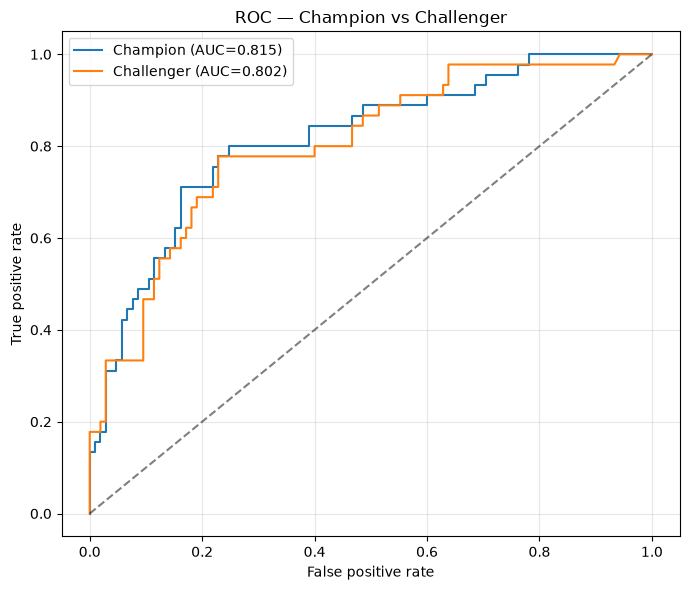

In [20]:


curves = roc_curves(y_test, pd_champion, pd_challenger_alt)
fig, ax = plt.subplots(figsize=(7, 6))
for name, (fpr, tpr, auc) in curves.items():
    ax.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC — Champion vs Challenger")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../models/roc_comparison.png", dpi=120)
plt.show()

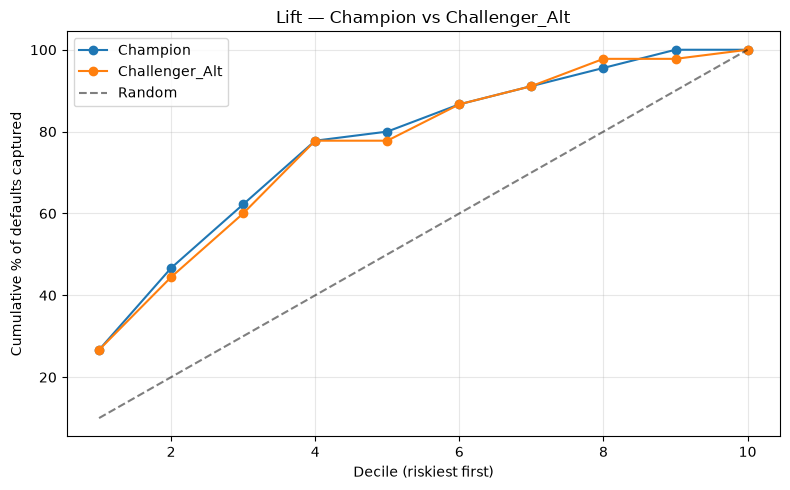

In [23]:
fig, ax = plt.subplots(figsize=(8, 5))

models = {
    "Champion": pd_champion,
    "Challenger_Alt": pd_challenger_alt,
}

for name, pd_values in models.items():
    df = pd.DataFrame({
        "pd": pd_values,
        "default": y_test,
    }).sort_values("pd", ascending=False).reset_index(drop=True)

    n = len(df)
    df["decile"] = np.repeat(np.arange(1, 11), int(np.ceil(n / 10)))[:n]

    rate = df.groupby("decile")["default"].mean().values
    cumulative = np.cumsum(rate) / np.sum(rate) * 100

    ax.plot(range(1, 11), cumulative, marker="o", label=name)

ax.plot(range(1, 11), np.arange(1, 11) * 10, "k--", alpha=0.5, label="Random")
ax.set_xlabel("Decile (riskiest first)")
ax.set_ylabel("Cumulative % of defaults captured")
ax.set_title("Lift — Champion vs Challenger_Alt")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../models/lift_comparison.png", dpi=120)
plt.show()

## 6. Verdict and artifacts

A challenger that lowers Gini-weighted cost but is not interpretable should remain a **benchmark**,
not replace the champion in a regulated environment.

In [24]:
comparison.to_json("../models/challenger_metrics.json", orient="records", indent=2)

champ_gini = gini(y_test, pd_champion)
chall_gini = gini(y_test, pd_challenger)
print(f"Champion Gini: {champ_gini:.4f} | Challenger Gini: {chall_gini:.4f}")
print(f"Delta Gini   : {chall_gini - champ_gini:+.4f}")
print(f"Delta cost   : {chall_cost - champ_cost:+.0f} units")
print("\nSaved models/challenger_metrics.json, roc_comparison.png, lift_comparison.png")

Champion Gini: 0.6309 | Challenger Gini: 0.5319
Delta Gini   : -0.0990
Delta cost   : +19 units

Saved models/challenger_metrics.json, roc_comparison.png, lift_comparison.png
